<a href="https://colab.research.google.com/github/Xyrfo/PCVK26_24_Rifo/blob/main/Week6_24.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# MODUL 6 - FILTER SPASIAL
## Citra Digital dan Visi Komputer
**Nama:** Rifo Anggi Barbara Danuarta  
**NIM:** 244107020063  
**No. Absen:** 24

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt
import math
import os

NAMA = 'Rifo Anggi Barbara Danuarta'
NIM = '244107020063'
print(NAMA, '-', NIM)

Rifo Anggi Barbara Danuarta - 244107020063


## Persiapan Citra dari Google Drive


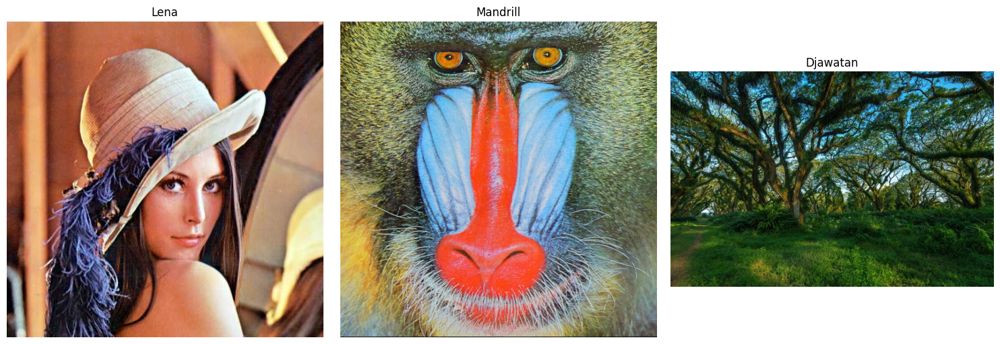

In [ ]:
!pip install -q gdown
import gdown

path_lena = '/content/drive/MyDrive/PCVK_2026/lena.jpg'
path_mandrill = '/content/drive/MyDrive/PCVK_2026/mandrill.tiff'
path_djawatan = '/content/drive/MyDrive/PCVK_2026/djawatan.jpg'


def baca_bgr(nama_file):
    citra = cv.imread(nama_file)

    if citra is None:
        raise ValueError(f'Citra tidak dapat dibaca: {nama_file}')

    return citra

img_lena = baca_bgr(path_lena)
img_mandrill = baca_bgr(path_mandrill)
img_djawatan = baca_bgr(path_djawatan)
img = img_lena
img_gray = cv.cvtColor(img, cv.COLOR_BGR2GRAY)

def show_side_by_side(images, titles, figsize=(15, 5)):
    plt.figure(figsize=figsize)
    for i, (im, title) in enumerate(zip(images, titles)):
        plt.subplot(1, len(images), i + 1)
        if len(im.shape) == 2:
            plt.imshow(im, cmap='gray')
        else:
            plt.imshow(cv.cvtColor(im, cv.COLOR_BGR2RGB))
        plt.title(title)
        plt.axis('off')
    plt.tight_layout()
    plt.show()

show_side_by_side([img_lena, img_mandrill, img_djawatan], ['Lena', 'Mandrill', 'Djawatan'])

## Praktikum Filter Spasial Manual



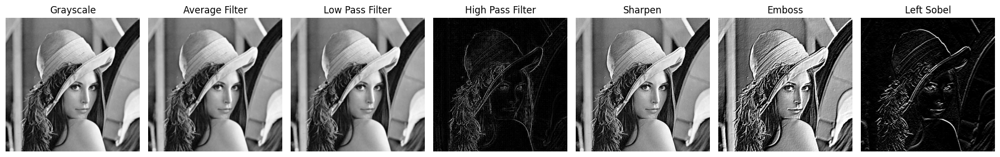

In [ ]:
def konvolusi(image, kernel, padding='edge'):
    image = image.astype(np.float32)
    kernel = np.asarray(kernel, dtype=np.float32)
    if kernel.ndim != 2 or kernel.shape[0] % 2 == 0 or kernel.shape[1] % 2 == 0:
        raise ValueError('Ukuran kernel harus ganjil dan berupa matriks 2D.')
    ky, kx = kernel.shape
    py, px = ky // 2, kx // 2
    padded = np.pad(image, ((py, py), (px, px)), mode=padding)
    kernel = np.flip(kernel)
    output = np.zeros_like(image, dtype=np.float32)
    for y in range(image.shape[0]):
        for x in range(image.shape[1]):
            output[y, x] = np.sum(padded[y:y+ky, x:x+kx] * kernel)
    return np.clip(output, 0, 255).astype(np.uint8)

kernels_manual = {
    'Average Filter': np.ones((3,3), np.float32) / 9,
    'Low Pass Filter': np.array([[1,1,1],[1,4,1],[1,1,1]], np.float32) / 12,
    'High Pass Filter': np.array([[-1,-1,-1],[-1,8,-1],[-1,-1,-1]], np.float32),
    'Sharpen': np.array([[0,-1,0],[-1,5,-1],[0,-1,0]], np.float32),
    'Emboss': np.array([[-2,-1,0],[-1,1,1],[0,1,2]], np.float32),
    'Left Sobel': np.array([[1,2,1],[0,0,0],[-1,-2,-1]], np.float32)
}
manual_results = [konvolusi(img_gray, k) for k in kernels_manual.values()]
show_side_by_side([img_gray] + manual_results, ['Grayscale'] + list(kernels_manual), figsize=(18, 8))

# FILTER LIBRARY DAN FILTER MODERN


## Percobaan 1: Filter Gaussian, Sharpen, dan Canny


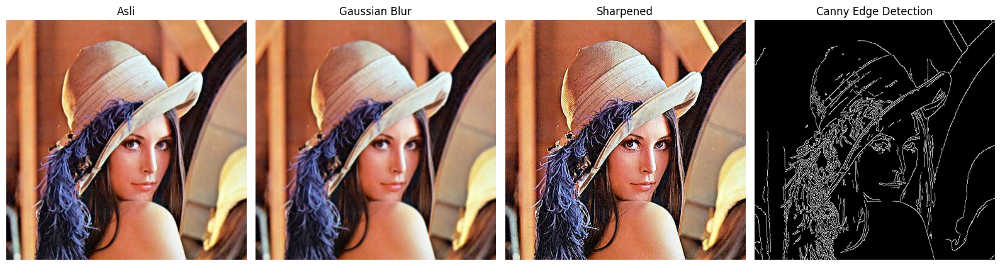

In [ ]:
blur = cv.GaussianBlur(img, (7, 7), 1)
edges = cv.Canny(cv.cvtColor(img, cv.COLOR_BGR2GRAY), 100, 200)
sharpen_kernel = np.array([[0,-1,0],[-1,5,-1],[0,-1,0]])
sharpened = cv.filter2D(img, -1, sharpen_kernel)
show_side_by_side([img, blur, sharpened, edges], ['Asli', 'Gaussian Blur', 'Sharpened', 'Canny Edge Detection'], figsize=(16,5))

## Percobaan 2: Bilateral Filtering dan Edge Preserving Filter


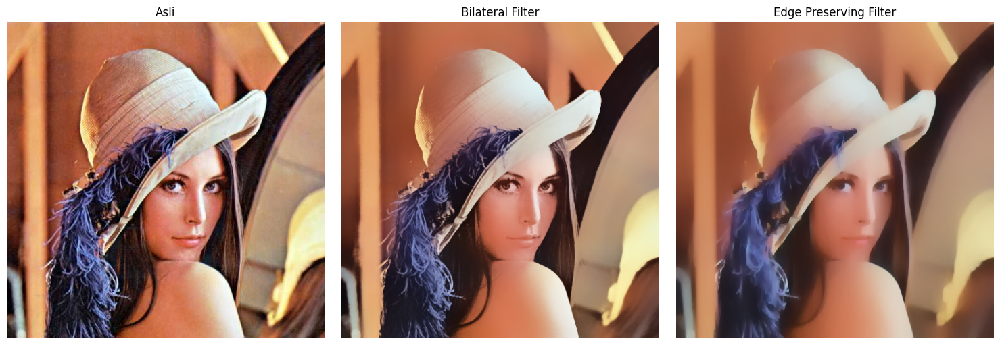

In [ ]:
bilateral = cv.bilateralFilter(img, 50, 100, 100)
try:
    edge_preserve = cv.edgePreservingFilter(img, flags=1, sigma_s=100, sigma_r=0.9)
except AttributeError:
    edge_preserve = cv.detailEnhance(img, sigma_s=100, sigma_r=0.9)
show_side_by_side([img, bilateral, edge_preserve], ['Asli', 'Bilateral Filter', 'Edge Preserving Filter'])

## Percobaan 3: Filtering pada CNN Feature Map


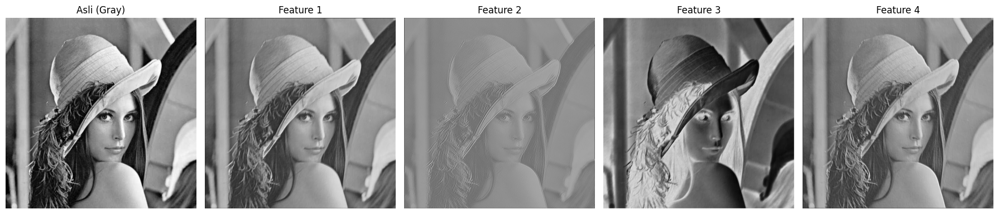

In [ ]:
import torch
import torch.nn as nn

class SimpleCNN(nn.Module):
    def __init__(self):
        super(SimpleCNN, self).__init__()
        self.conv1 = nn.Conv2d(1, 4, kernel_size=3, stride=1, padding=1)
    def forward(self, x):
        return self.conv1(x)

model = SimpleCNN()
img_tensor = torch.tensor(img_gray, dtype=torch.float32).unsqueeze(0).unsqueeze(0) / 255.0
with torch.no_grad():
    features = model(img_tensor)
feature_maps = [features[0, i].numpy() for i in range(features.shape[1])]
show_side_by_side([img_gray] + feature_maps, ['Asli (Gray)'] + [f'Feature {i+1}' for i in range(len(feature_maps))], figsize=(18,5))

## Percobaan 4: Beauty dan Old/Vintage Filter

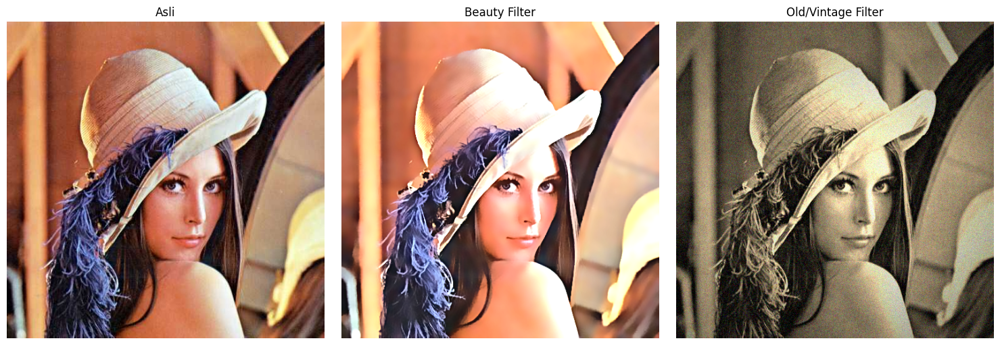

In [ ]:
smooth = cv.bilateralFilter(img, d=15, sigmaColor=75, sigmaSpace=75)
gaussian = cv.GaussianBlur(smooth, (0,0), 3)
beauty_sharp = cv.addWeighted(smooth, 1.5, gaussian, -0.5, 0)
beauty = cv.convertScaleAbs(beauty_sharp, alpha=1.2, beta=15)

sepia_kernel = np.array([[0.272,0.534,0.131],[0.349,0.686,0.168],[0.393,0.769,0.189]])
sepia = cv.transform(img, sepia_kernel)
sepia = np.clip(sepia, 0, 255).astype(np.uint8)
rows, cols = img.shape[:2]
kernel_x = cv.getGaussianKernel(cols, cols*0.6)
kernel_y = cv.getGaussianKernel(rows, rows*0.6)
mask = (kernel_y @ kernel_x.T); mask = mask / mask.max()
vintage = sepia.astype(np.float32) * mask[..., None]
rng = np.random.default_rng(24)
vintage = np.clip(vintage + rng.normal(0, 15, vintage.shape), 0, 255).astype(np.uint8)
show_side_by_side([img, beauty, vintage], ['Asli', 'Beauty Filter', 'Old/Vintage Filter'], figsize=(15,5))

## Percobaan 5: Filter Anime / Cartoon


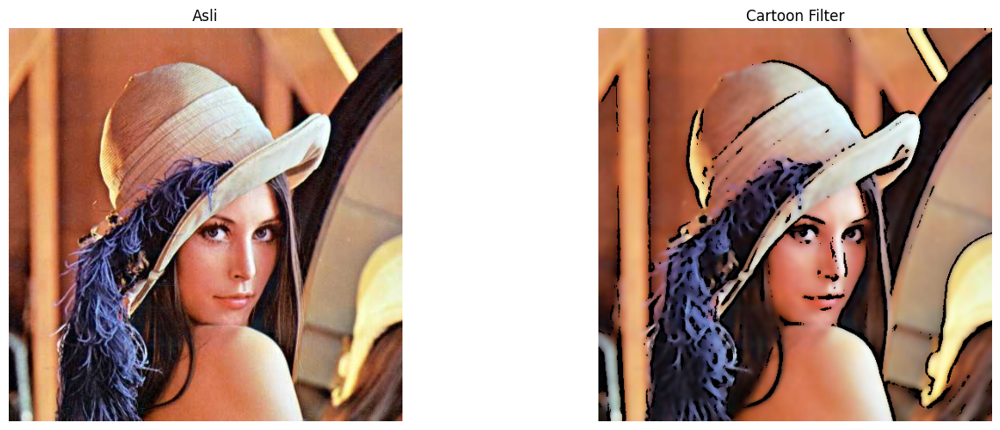

In [ ]:
gray_cartoon = cv.cvtColor(img, cv.COLOR_BGR2GRAY)
gray_blur = cv.medianBlur(gray_cartoon, 7)
edges_cartoon = cv.adaptiveThreshold(gray_blur, 255, cv.ADAPTIVE_THRESH_MEAN_C, cv.THRESH_BINARY, 9, 9)
color_cartoon = cv.bilateralFilter(img, d=9, sigmaColor=200, sigmaSpace=200)
cartoon = cv.bitwise_and(color_cartoon, color_cartoon, mask=edges_cartoon)
show_side_by_side([img, cartoon], ['Asli', 'Cartoon Filter'])

## Percobaan 6: Night Filter


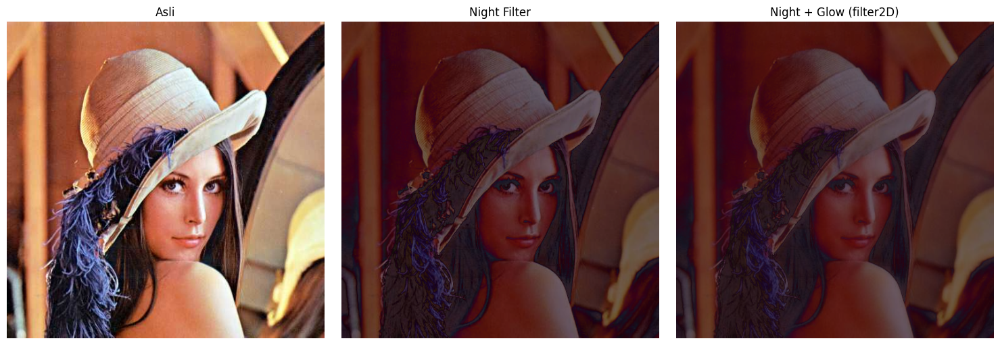

In [ ]:
night = cv.convertScaleAbs(img, alpha=0.6, beta=-40)
blue_tint = np.full_like(night, (50, 0, 100))
night = cv.addWeighted(night, 0.8, blue_tint, 0.2, 0)
kernel_glow = np.ones((15,15), np.float32) / 225
glow = cv.filter2D(night, -1, kernel_glow)
night_glow = cv.addWeighted(night, 0.7, glow, 0.3, 0)
show_side_by_side([img, night, night_glow], ['Asli', 'Night Filter', 'Night + Glow (filter2D)'])

## Percobaan 7: Filter Pagi dan Pagi + Kabut


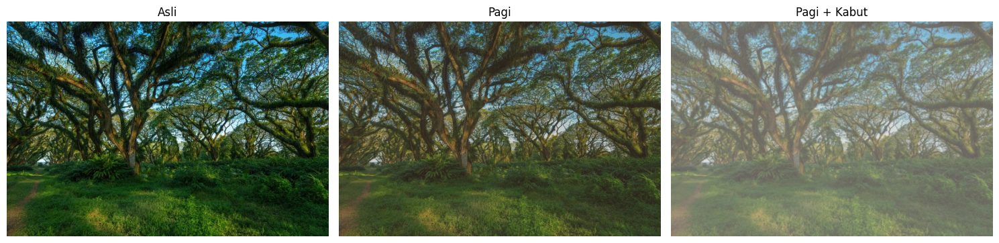

In [ ]:
alpha, beta = 0.9, 20
soft = cv.convertScaleAbs(img_djawatan, alpha=alpha, beta=beta)
warm_tint = np.full_like(soft, (40, 70, 120))
pagi = cv.addWeighted(soft, 0.8, warm_tint, 0.2, 0)
kernel_haze = cv.getGaussianKernel(3, 3)
kernel_haze = kernel_haze @ kernel_haze.T
kabut = cv.filter2D(pagi, -1, kernel_haze)
white_layer = np.full_like(pagi, 255)
kabut = cv.addWeighted(kabut, 0.7, white_layer, 0.3, 0)
show_side_by_side([img_djawatan, pagi, kabut], ['Asli', 'Pagi', 'Pagi + Kabut'])

# TUGAS PRAKTIKUM


## Tugas 1: Perbandingan Mean Filter dan Median Filter pada Noise Salt and Pepper

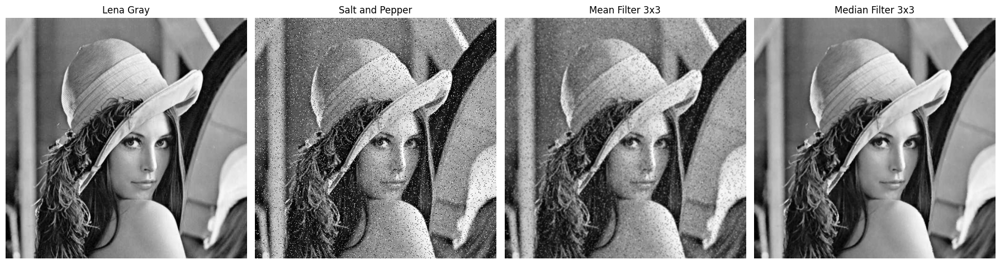

In [ ]:
def tambah_salt_pepper(image, amount=0.08, seed=24):
    rng = np.random.default_rng(seed)
    noisy = image.copy()
    jumlah = int(amount * image.size)
    indeks = rng.choice(image.size, jumlah, replace=False)
    noisy.flat[indeks[:len(indeks)//2]] = 255
    noisy.flat[indeks[len(indeks)//2:]] = 0
    return noisy

lena_gray = cv.cvtColor(img_lena, cv.COLOR_BGR2GRAY)
noisy = tambah_salt_pepper(lena_gray)
mean_result = konvolusi(noisy, np.ones((3,3), np.float32) / 9)
median_result = cv.medianBlur(noisy, 3)
show_side_by_side([lena_gray, noisy, mean_result, median_result], ['Lena Gray', 'Salt and Pepper', 'Mean Filter 3x3', 'Median Filter 3x3'], figsize=(18,5))

**Analisis:** Mean Filter ikut menghitung piksel ekstrem bernilai 0 dan 255 sehingga noise menyebar dan tepi menjadi kabur. Median Filter memilih nilai tengah pada jendela piksel, sehingga lebih tahan terhadap noise salt-and-pepper dan menghasilkan citra yang lebih bersih.

## Tugas 2: Evaluasi Ukuran Kernel Sharpening

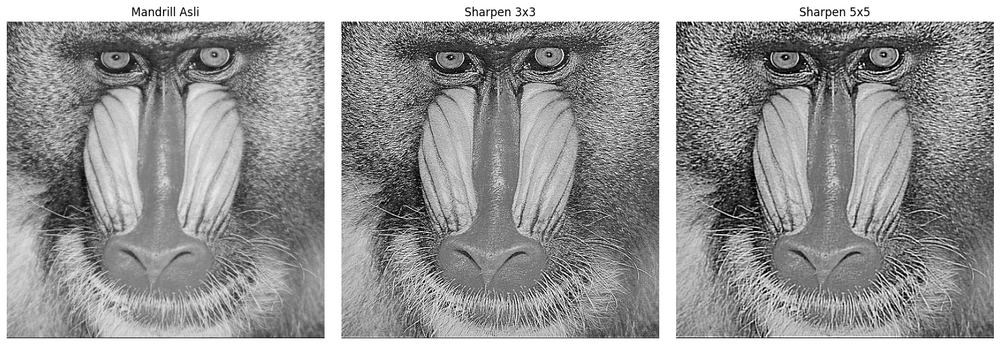

In [ ]:
mandrill_gray = cv.cvtColor(img_mandrill, cv.COLOR_BGR2GRAY)
sharpen_3x3 = np.array([[0,-1,0],[-1,5,-1],[0,-1,0]], np.float32)
sharpen_5x5 = np.array([[-1,-1,-1,-1,-1],[-1,2,2,2,-1],[-1,2,8,2,-1],[-1,2,2,2,-1],[-1,-1,-1,-1,-1]], np.float32) / 8
hasil_3x3 = konvolusi(mandrill_gray, sharpen_3x3)
hasil_5x5 = konvolusi(mandrill_gray, sharpen_5x5)
show_side_by_side([mandrill_gray, hasil_3x3, hasil_5x5], ['Mandrill Asli', 'Sharpen 3x3', 'Sharpen 5x5'])

**Analisis:** Kernel 3x3 lebih sesuai untuk penggunaan sehari-hari karena menajamkan tepi dengan distorsi lebih kecil. Kernel 5x5 memiliki area pengaruh lebih luas dan dapat memperjelas detail lebih kuat, tetapi juga lebih mudah memperkuat noise atau menghasilkan halo.

## Tugas 3: Filter Kartun Sederhana

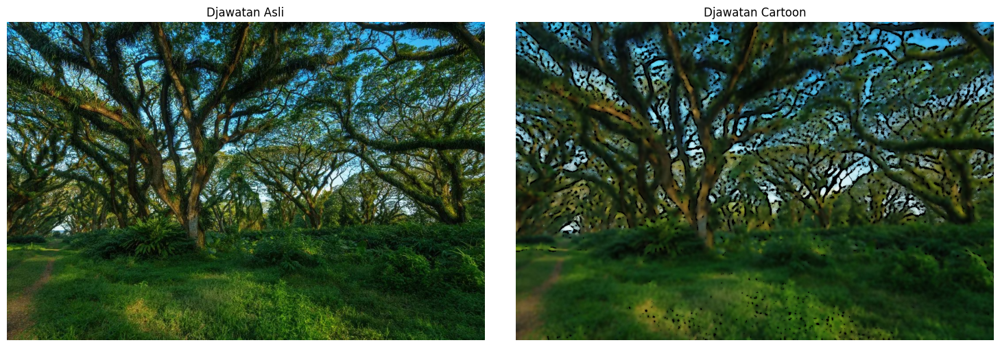

In [ ]:
def kartun(image):
    gray = cv.cvtColor(image, cv.COLOR_BGR2GRAY)
    gray_blur = cv.medianBlur(gray, 7)
    edges = cv.adaptiveThreshold(gray_blur, 255, cv.ADAPTIVE_THRESH_MEAN_C, cv.THRESH_BINARY, 9, 9)
    color = cv.bilateralFilter(image, d=9, sigmaColor=200, sigmaSpace=200)
    return cv.bitwise_and(color, color, mask=edges)

cartoon_djawatan = kartun(img_djawatan)
show_side_by_side([img_djawatan, cartoon_djawatan], ['Djawatan Asli', 'Djawatan Cartoon'])

**Analisis:** Bilateral Filter meratakan warna pada area yang serupa sambil mempertahankan batas objek. Adaptive Thresholding menghasilkan garis tepi lokal, kemudian operasi `bitwise_and` menggabungkan warna halus dan garis sehingga terbentuk efek kartun.

# Kesimpulan
Filter spasial menggunakan kernel atau operasi tetangga untuk mengubah citra. Percobaan 1–7 menunjukkan penggunaan filter library, filter modern, feature map CNN, serta kombinasi filter tradisional. Tugas praktikum membuktikan bahwa Median Filter lebih baik untuk noise salt-and-pepper, kernel sharpening 3x3 lebih seimbang untuk penggunaan umum, dan efek kartun dapat dibuat dengan kombinasi bilateral filter serta deteksi tepi.